# Linear regression and Gaussian log likelihood

Compares OLS and SGD on a noisy synthetic two-feature problem and calculates their Gaussian residual likelihood.

Saved outputs are from the original coursework run, before the small fixes in this copy. The notebooks have not been rerun.


In [ ]:
#Import needed packages
import numpy as np
import gc
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import pandas as pd
import warnings
warnings.filterwarnings('ignore', module='sklearn')
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from math import sqrt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import statsmodels.api as sm
from sklearn.metrics import r2_score
import seaborn as sns
from scipy.optimize import minimize 



def log_likelihood_linear_regression(beta, sigma_squared, X, y, intercept=0.0):
    """
    Calculate the log-likelihood for linear regression with normally distributed errors.

    :param beta: Coefficients for the linear regression model.
    :param sigma_squared: Variance of the error term.
    :param X: Design matrix (independent variables).
    :param y: Vector of dependent variable observations.
    :return: Log-likelihood value.
    """
    n = len(y)
    residuals = y - (np.dot(X, beta) + intercept)
    log_likelihood = -0.5 * n * np.log(2 * np.pi) - 0.5 * n * np.log(sigma_squared) - (1 / (2 * sigma_squared)) * np.sum(residuals**2)
    return log_likelihood

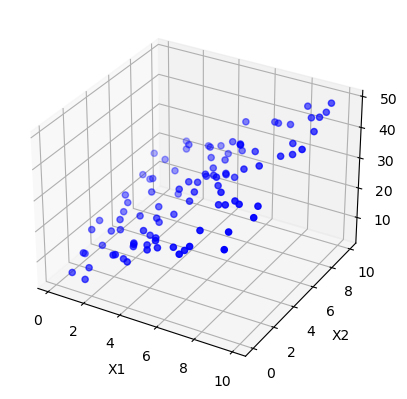

In [ ]:
np.random.seed(42)
# Parameters for the linear relationship with two variables
slope_1 = 3
slope_2 = 1.5
intercept = 4


# Generating random data for the two independent variables
x1 = np.random.rand(100) * 10  # 100 random values for x1 between 0 and 10
x2 = np.random.rand(100) * 10  # 100 random values for x2 between 0 and 10

# Applying the linear equation (y = m1*x1 + m2*x2 + c)
y = slope_1 * x1 + slope_2 * x2 + intercept

# Adding some noise
noise = np.random.randn(100) * 2
y_noisy = y + noise

# Creating a DataFrame
df = pd.DataFrame({
    'X1': x1,
    'X2': x2,
    'Y': y_noisy
})

df.head()  # Displaying the first few rows of the dataset
# Create a 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the points
ax.scatter(x1, x2, y_noisy, c='b', marker='o')

# Set labels
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('Y')

# Show the plot
plt.show()

# Your design matrix and dependent variable
X = df.drop("Y", axis=1)
Y = df["Y"]

In [ ]:
# Create and train the Linear Regression model
lin_reg = LinearRegression()
lin_reg.fit(X, Y)

# Predicting the Test set results
y_pred = lin_reg.predict(X)

print("NORMAL LINEAR REGRESSION")

# Your model coefficients and intercept
beta = lin_reg.coef_
inter = lin_reg.intercept_
print("Coef:", beta, "\nIntercept:", inter)

residuals = y_pred - Y
rmse = sqrt(mean_squared_error(Y, y_pred))
print("Rmse:", rmse)

r_squared = r2_score(Y, y_pred)
print("R-squared:", r_squared)

# Estimate of the variance of the error term
sigma_squared = np.var(residuals)
print("Var:", sigma_squared)

res = log_likelihood_linear_regression(beta, sigma_squared, X, Y, intercept=inter)
print("Log_Like:", res)

like = np.exp(res)
print("Likelihood (may underflow):", like)

NORMAL LINEAR REGRESSION
Coef: [3.02830751 1.58967706] 
Intercept: 3.450610135993241
Rmse: 1.9173157126003477
R-squared: 0.9652209379394376
Var: 3.67609954178418

In [ ]:
#IMPLEMENTED WITH STOCHASTIC GRADIENT DESCEND

# Create and train the SGD Regressor model
sgd_reg = SGDRegressor(max_iter=1000, tol=1e-3, random_state=42)
sgd_reg.fit(X, Y)

# Predicting the Test set result
y_pred = sgd_reg.predict(X)

print("STOCHASTIC GRADIENT DESCEND")

# Your model coefficients and intercept
beta = sgd_reg.coef_
inter = sgd_reg.intercept_
print("Coef:", beta, "\nIntercept:", inter)

residuals = y_pred - Y
rmse = sqrt(mean_squared_error(Y, y_pred))
print("Rmse:", rmse)

r_squared = r2_score(Y, y_pred)
print("R-squared:", r_squared)

# Estimate of the variance of the error term
sigma_squared = np.var(residuals)
print("Var:", sigma_squared)

res = log_likelihood_linear_regression(beta, sigma_squared, X, Y, intercept=inter)
print("Log_Like:", res)

like = np.exp(res)
print("Likelihood (may underflow):", like)

STOCHASTIC GRADIENT DESCEND
Coef: [3.17985783 1.70912577] 
Intercept: [2.24431035]
Rmse: 2.0067682384330223
R-squared: 0.9618999943325452
Var: 4.018096858059127